# Nemotron 3.5 Transcribe

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cobusgreyling/nemotron-3.5-transcribe/blob/main/notebooks/nemotron_3_5_transcribe.ipynb)

One recording. A transcript you can use.

This notebook runs the walkthrough in the repository. It loads the local clip, the seven prompts, the language table, and the JSON the console shows.

Nemotron 3.5 Transcribe is the promptable file model: about 30 billion parameters, about 4 billion active, a file up to 60 minutes, and a 64,000-token budget shared by the audio, the prompt, and the answer. Nemotron 3.5 ASR is the separate 600-million-parameter streaming model. The Transcribe weights are not in this repository. These cells check the request the showcase already makes.


In [1]:
from pathlib import Path
import re
import subprocess

REPO_URL = "https://github.com/cobusgreyling/nemotron-3.5-transcribe.git"


def find_repo() -> Path:
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / "app.js").is_file() and (candidate / "assets" / "demo.wav").is_file():
            return candidate
    dest = Path("/content/nemotron-3.5-transcribe")
    if not (dest / "app.js").is_file():
        if not Path("/content").is_dir():
            raise FileNotFoundError(
                "Open this notebook from a clone, or run it on Colab so it can clone the repository."
            )
        subprocess.check_call(["git", "clone", "--depth", "1", REPO_URL, str(dest)])
    return dest


def parse_showcase(root: Path) -> dict:
    text = (root / "app.js").read_text(encoding="utf-8")
    phrases = [
        {
            "t0": float(t0),
            "t1": float(t1),
            "speaker": int(speaker),
            "role": role,
            "text": phrase,
        }
        for t0, t1, speaker, role, phrase in re.findall(
            r'\{\s*t0:\s*([0-9.]+),\s*t1:\s*([0-9.]+),\s*speaker:\s*(\d+),\s*role:\s*"([^"]*)",\s*text:\s*"([^"]*)"\s*\}',
            text,
        )
    ]
    prompt_block = re.search(r"const PROMPTS = \{([\s\S]*?)\};", text)
    if prompt_block is None:
        raise ValueError("PROMPTS block is missing from app.js")
    prompts = dict(re.findall(r'(\w+):\s*"([^"]*)"', prompt_block.group(1)))
    languages = [
        (name, translate == "true", speakers == "true")
        for name, translate, speakers in re.findall(
            r'\["([^"]+)",\s*(true|false),\s*(true|false)\]',
            text,
        )
    ]
    duration_match = re.search(r"const DURATION = ([0-9.]+);", text)
    payload_match = re.search(r"function payload\(\) \{([\s\S]*?)\n\}", text)
    if duration_match is None or payload_match is None:
        raise ValueError("DURATION or payload() is missing from app.js")
    payload = payload_match.group(1)
    context_match = re.search(r"context:\s*\[([^\]]*)\]", payload)
    if context_match is None:
        raise ValueError("payload() context list is missing from app.js")
    return {
        "phrases": phrases,
        "prompts": prompts,
        "languages": languages,
        "duration": float(duration_match.group(1)),
        "model": re.search(r'model:\s*"([^"]+)"', payload).group(1),
        "mode": re.search(r'mode:\s*"([^"]+)"', payload).group(1),
        "note": re.search(r'note:\s*"([^"]+)"', payload).group(1),
        "answer": re.search(r'answer:\s*"([^"]+)"', payload).group(1),
        "context": re.findall(r'"([^"]+)"', context_match.group(1)),
    }


root = find_repo()
show = parse_showcase(root)
print("repo:", root.name)
print("clip:", (root / "assets" / "demo.wav").name)
print("prompts:", ", ".join(show["prompts"]))
print("languages:", len(show["languages"]))
print("phrases:", len(show["phrases"]))


repo: nemotron-3.5-transcribe
clip: demo.wav
prompts: signal, words, languages, speakers, timing, json, events
languages: 40
phrases: 3


## The clip

`assets/demo.wav` is the local three-voice file: agent, customer, supervisor. The console describes it as mono, 16 kHz, and 11 seconds. Phrase times in `app.js` are marked by hand so the playhead has something to follow. They are the demo marks, and the cell below checks the file against those marks.


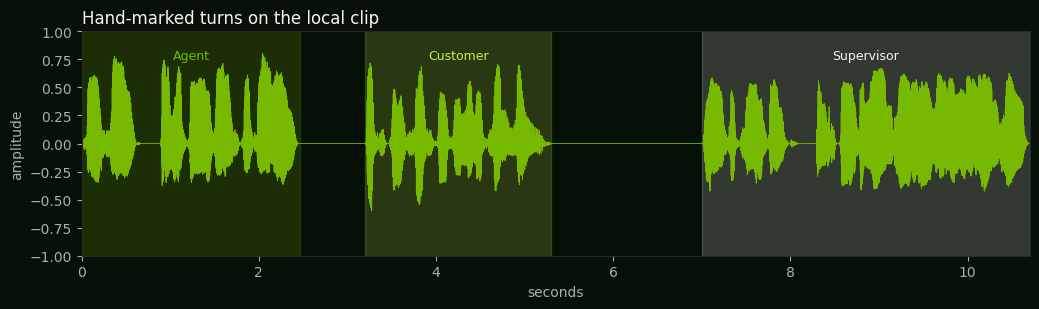

demo.wav: mono, 16000 Hz, 16-bit, 10.705s
playhead duration in app.js: 10.70s


In [2]:
%matplotlib inline
import wave

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Audio, display

wav_path = root / "assets" / "demo.wav"
with wave.open(str(wav_path)) as handle:
    channels = handle.getnchannels()
    sample_width = handle.getsampwidth()
    rate = handle.getframerate()
    frame_count = handle.getnframes()
    raw = handle.readframes(frame_count)

file_seconds = frame_count / rate
assert channels == 1, channels
assert sample_width == 2, sample_width
assert rate == 16000, rate
assert file_seconds >= show["duration"], file_seconds
assert file_seconds < 11.0, file_seconds
assert abs(file_seconds - show["duration"]) < 0.02, (file_seconds, show["duration"])

samples = np.frombuffer(raw, dtype="<i2").astype(np.float32) / 32768.0
colors = {1: "#76b900", 2: "#c6f04d", 3: "#f4f7ef"}

fig, ax = plt.subplots(figsize=(10.5, 3.2), facecolor="#071007")
ax.set_facecolor("#071007")
ax.plot(np.arange(samples.size) / rate, samples, color="#76b900", linewidth=0.6)
for phrase in show["phrases"]:
    ax.axvspan(phrase["t0"], phrase["t1"], color=colors[phrase["speaker"]], alpha=0.18)
    ax.text(
        (phrase["t0"] + phrase["t1"]) / 2,
        0.92,
        phrase["role"],
        color=colors[phrase["speaker"]],
        ha="center",
        va="top",
        fontsize=9,
        transform=ax.get_xaxis_transform(),
    )
ax.set_xlim(0, file_seconds)
ax.set_ylim(-1, 1)
ax.set_xlabel("seconds", color="#a7b3a4")
ax.set_ylabel("amplitude", color="#a7b3a4")
ax.set_title("Hand-marked turns on the local clip", color="#f3f6ef", loc="left")
ax.tick_params(colors="#a7b3a4")
for spine in ax.spines.values():
    spine.set_color("#243024")
fig.tight_layout()
plt.show()

print(f"demo.wav: mono, {rate} Hz, {sample_width * 8}-bit, {file_seconds:.3f}s")
print(f"playhead duration in app.js: {show['duration']:.2f}s")
display(Audio(raw, rate=rate))


## Seven prompts, one clip

The console keeps the audio fixed and changes the instruction. These strings are read from `PROMPTS` in `app.js`.


In [3]:
expected_tabs = ["signal", "words", "languages", "speakers", "timing", "json", "events"]
assert list(show["prompts"]) == expected_tabs, list(show["prompts"])
for name in expected_tabs:
    line = show["prompts"][name]
    assert line.startswith("> "), line
    print(f"{name:10} {line}")


signal     > Listening to the local clip.
words      > Transcribe it. Names: Greyling. Terms: invoice, callback.
languages  > This clip is English. A translate prompt would be a second instruction on the same audio.
speakers   > Label the speakers. Up to 8, in 13 languages. This clip uses 3.
timing     > Add phrase timing. These marks are hand-timed for the demo playhead.
json       > Return one JSON object the caller can parse.
events     > List the speaker changes.


## Forty languages

Every language in the table transcribes, and the model can switch language mid-sentence. English is the pivot, so the other 31 are the translate set. A speaker flag marks the 13 languages that can label up to 8 speakers. The names below are the chip list in `app.js`.


In [4]:
NAMED_SPEAKER_LANGUAGES = [
    "Arabic",
    "Mandarin",
    "English",
    "French",
    "German",
    "Hindi",
    "Italian",
    "Japanese",
    "Korean",
    "Portuguese",
    "Russian",
    "Spanish",
    "Thai",
]

languages = show["languages"]
assert len(languages) == 40, len(languages)
assert len({name for name, _, _ in languages}) == 40

translate = [name for name, can_translate, _ in languages if can_translate and name != "English"]
speakers = [name for name, _, can_label in languages if can_label]
assert len(translate) == 31, translate
assert len(speakers) == 13, speakers
assert ("English", True, True) in [(name, a, b) for name, a, b in languages]
for required in NAMED_SPEAKER_LANGUAGES:
    assert any(required in name for name in speakers), required

print(f"{len(languages)} transcribe")
print(f"{len(translate)} translate to and from English")
print(f"{len(speakers)} label speakers: {', '.join(speakers)}")
print()
print(f"{'language':22} {'translate':10} speakers")
for name, can_translate, can_label in languages:
    print(f"{name:22} {str(can_translate):10} {str(can_label)}")


40 transcribe
31 translate to and from English
13 label speakers: Arabic, Chinese Mandarin, English, French, German, Hindi, Italian, Japanese, Korean, Portuguese, Russian, Spanish, Thai

language               translate  speakers
Arabic                 True       True
Bengali                False      False
Bulgarian              True       False
Chinese Mandarin       True       True
Croatian               True       False
Czech                  True       False
Danish                 True       False
Dutch                  True       False
English                True       True
Estonian               True       False
Finnish                True       False
French                 True       True
German                 True       True
Greek                  True       False
Hebrew                 True       False
Hindi                  True       True
Hungarian              True       False
Indonesian             False      False
Italian                True       True
Japanese         

## Hand-marked turns

Three Mac voices, one after another. The times belong to the demo playhead.


In [5]:
phrases = show["phrases"]
assert len(phrases) == 3, phrases
assert [phrase["role"] for phrase in phrases] == ["Agent", "Customer", "Supervisor"]
assert [phrase["speaker"] for phrase in phrases] == [1, 2, 3]
assert phrases[0]["t0"] == 0.0
assert phrases[-1]["t1"] == show["duration"]
for earlier, later in zip(phrases, phrases[1:]):
    assert earlier["t1"] <= later["t0"], (earlier, later)
    assert later["t0"] - earlier["t1"] > 0.5
for phrase in phrases:
    assert phrase["text"].strip()
    print(
        f"{phrase['t0']:5.2f}–{phrase['t1']:5.2f}s  "
        f"Speaker {phrase['speaker']} {phrase['role']:12} {phrase['text']}"
    )

print()
for index, phrase in enumerate(phrases):
    if index == 0:
        label = "speech starts"
    else:
        previous = phrases[index - 1]["speaker"]
        label = f"speaker change {previous} → {phrase['speaker']}"
    print(f"{phrase['t0']:5.2f}s  {label}")
print(f"{show['duration']:5.2f}s  end of file")


 0.00– 2.47s  Speaker 1 Agent        Please hold. I have the invoice for Greyling.
 3.20– 5.30s  Speaker 2 Customer     It still says forty minutes on hold.
 7.00–10.70s  Speaker 3 Supervisor   Log a callback, and spell the name G R E Y L I N G.

 0.00s  speech starts
 3.20s  speaker change 1 → 2
 7.00s  speaker change 2 → 3
10.70s  end of file


## The JSON a caller would parse

`payload()` in `app.js` is the shape of a result. The note on that object says it is demo-shaped. This cell rebuilds it from the parsed phrases and checks the fields the console prints.


In [6]:
import json

payload = {
    "model": show["model"],
    "mode": show["mode"],
    "note": show["note"],
    "context": show["context"],
    "phrases": [
        {
            "start": phrase["t0"],
            "end": phrase["t1"],
            "speaker": phrase["speaker"],
            "role": phrase["role"],
            "text": phrase["text"],
        }
        for phrase in show["phrases"]
    ],
    "answer": show["answer"],
}

assert payload["model"] == "nemotron-3.5-transcribe"
assert payload["mode"] == "demo"
assert payload["note"] == "Shape of a result. Not model output."
assert payload["context"] == ["Greyling", "invoice", "callback"]
assert payload["answer"] == "The customer was on hold for forty minutes."
assert len(payload["phrases"]) == 3
speakers = {phrase["speaker"] for phrase in payload["phrases"]}
assert speakers == {1, 2, 3}
assert len(speakers) <= 8
for phrase in payload["phrases"]:
    assert 0 <= phrase["start"] < phrase["end"] <= show["duration"]

spoken = " ".join(phrase["text"] for phrase in show["phrases"]).lower()
for term in payload["context"]:
    assert term in show["prompts"]["words"], term
    assert term.lower() in spoken, term

print(json.dumps(payload, indent=2))


{
  "model": "nemotron-3.5-transcribe",
  "mode": "demo",
  "note": "Shape of a result. Not model output.",
  "context": [
    "Greyling",
    "invoice",
    "callback"
  ],
  "phrases": [
    {
      "start": 0.0,
      "end": 2.47,
      "speaker": 1,
      "role": "Agent",
      "text": "Please hold. I have the invoice for Greyling."
    },
    {
      "start": 3.2,
      "end": 5.3,
      "speaker": 2,
      "role": "Customer",
      "text": "It still says forty minutes on hold."
    },
    {
      "start": 7.0,
      "end": 10.7,
      "speaker": 3,
      "role": "Supervisor",
      "text": "Log a callback, and spell the name G R E Y L I N G."
    }
  ],
  "answer": "The customer was on hold for forty minutes."
}


## Five jobs, same audio

The page lists five instructions one request can carry. Each one points at a prompt already stored in the console. The term list is the context on the words prompt: Greyling, invoice, callback.


In [7]:
jobs = [
    ("Transcribe", "words"),
    ("Translate", "languages"),
    ("Label speakers", "speakers"),
    ("Use the term list", "words"),
    ("Ask about the audio", "json"),
]
assert {key for _, key in jobs} <= set(show["prompts"])
for title, key in jobs:
    print(f"{title}")
    print(f"  {show['prompts'][key]}")
print()
print("Term list:", ", ".join(show["context"]))
print("Answer shape:", show["answer"])


Transcribe
  > Transcribe it. Names: Greyling. Terms: invoice, callback.
Translate
  > This clip is English. A translate prompt would be a second instruction on the same audio.
Label speakers
  > Label the speakers. Up to 8, in 13 languages. This clip uses 3.
Use the term list
  > Transcribe it. Names: Greyling. Terms: invoice, callback.
Ask about the audio
  > Return one JSON object the caller can parse.

Term list: Greyling, invoice, callback
Answer shape: The customer was on hold for forty minutes.


## Throughput figures from the post

RTFx is the real-time factor in `BLOG.md`. A figure of 100x means one second of GPU work clears about 100 seconds of audio. The table is NVIDIA's. This notebook reads it and does not measure it.


In [8]:
blog = (root / "BLOG.md").read_text(encoding="utf-8")
assert "Granary-v2" in blog
assert "What to test" in blog

rows = []
for line in blog.splitlines():
    if not line.startswith("|"):
        continue
    cells = [cell.strip() for cell in line.strip().strip("|").split("|")]
    if len(cells) != 4 or cells[0] in {"Machine", ""} or cells[0].startswith("-"):
        continue
    rows.append(cells)

assert len(rows) == 7, rows
assert rows[0][0] == "Jetson AGX Thor"
assert rows[0][1] == "106x"
assert rows[-1][0] == "B200 / GB200"
assert rows[-1][1] == "3,064x"
print(f"{'machine':28} {'RTFx':8} {'100 hours':12} how to run it")
for machine, rtfx, hours, how in rows:
    print(f"{machine:28} {rtfx:8} {hours:12} {how}")
print("Source: BLOG.md. Not measured in this notebook.")


machine                      RTFx     100 hours    how to run it
Jetson AGX Thor              106x     57 min       NeMo-Speech.cpp, JetPack
RTX Spark (N1X)              274x     22 min       NeMo-Speech.cpp, Windows 11 ARM64
DGX Spark                    370x     16 min       NeMo-Speech.cpp or NIM
RTX 5090                     587x     10 min       NIM
H100 / H200                  1,340x   4.5 min      NIM
RTX PRO 6000 Blackwell       2,325x   2.6 min      NIM
B200 / GB200                 3,064x   2 min        NIM
Source: BLOG.md. Not measured in this notebook.


## When the weights are on a GPU

The post names four checks for a machine that has the checkpoint. This repository does not contain that checkpoint, and this notebook does not send the clip to another model. The last cell records the four checks as still waiting, and confirms the loader stops.


In [9]:
def load_weights(repo: Path) -> None:
    checkpoint = repo / "weights"
    if not checkpoint.exists():
        raise FileNotFoundError(
            "The Nemotron 3.5 Transcribe checkpoint is not in this repository."
        )


waiting = [
    "A language switch, in any of the 40 languages.",
    "A domain word, once with the term list and once without it.",
    "Speaker labels on a multi-speaker clip, in one of the 13 languages.",
    "Throughput, with the full test setup written down.",
]
try:
    load_weights(root)
except FileNotFoundError as exc:
    stopped = str(exc)
else:
    stopped = ""
assert stopped == "The Nemotron 3.5 Transcribe checkpoint is not in this repository."
assert not (root / "weights").exists()

print(stopped)
print()
print("Waiting on the checkpoint:")
for item in waiting:
    print(f"  {item}")
print()
print("clip        ok")
print("languages   ok")
print("prompts     ok")
print("payload     ok")
print("weights     absent")


The Nemotron 3.5 Transcribe checkpoint is not in this repository.

Waiting on the checkpoint:
  A language switch, in any of the 40 languages.
  A domain word, once with the term list and once without it.
  Speaker labels on a multi-speaker clip, in one of the 13 languages.
  Throughput, with the full test setup written down.

clip        ok
languages   ok
prompts     ok
payload     ok
weights     absent


Lab code in this repository is Apache-2.0. The NVIDIA weights are not included.
